### Is CUDA available or not ?

In [18]:
import fastai.torch_core as ft
import torch

print("CUDA Available:        ", torch.cuda.is_available())
print("Device Count:          ", torch.cuda.device_count())
print("Active GPU:            ", torch.cuda.get_device_name(0))
print(
    "Fastai Default Device: ", ft.default_device()
)  # Should print device(type='cuda', index=0)


CUDA Available:         True
Device Count:           1
Active GPU:             NVIDIA GeForce RTX 5060 Ti
Fastai Default Device:  cuda:0


## Is it a bird?

In [19]:
#NB: Kaggle requires phone verification to use the internet or a GPU. If you haven't done that yet, the cell below will fail
#    This code is only here to check that your internet is enabled. It doesn't do anything else.
#    Here's a help thread on getting your phone number verified: https://www.kaggle.com/product-feedback/135367

import socket,warnings
try:
    socket.setdefaulttimeout(1)
    socket.socket(socket.AF_INET, socket.SOCK_STREAM).connect(('1.1.1.1', 53))
except socket.error as ex: raise Exception("STOP: No internet. Click '>|' in top right and set 'Internet' switch to on")

/tmp/ipykernel_41/1663014884.py:8: ResourceWarning: unclosed <socket.socket fd=78, family=2, type=1, proto=0, laddr=('172.18.0.3', 59584), raddr=('1.1.1.1', 53)>
  socket.socket(socket.AF_INET, socket.SOCK_STREAM).connect(('1.1.1.1', 53))


In [20]:
# It's a good idea to ensure you're running the latest version of any libraries you need.
# `!pip install -Uqq <libraries>` upgrades to the latest version of <libraries>
# NB: You can safely ignore any warnings or errors pip spits out about running as root or incompatibilities
import os
iskaggle = os.environ.get('KAGGLE_KERNEL_RUN_TYPE', '')

if iskaggle:
    !pip install -Uqq fastai ddgs duckduckgo_search


In 2015 the idea of creating a computer system that could recognise birds was considered so outrageously challenging that it was the basis of [this XKCD joke](https://xkcd.com/1425/):

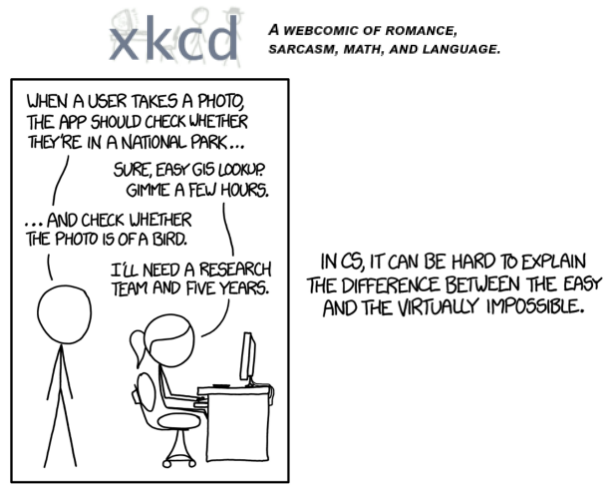

But today, we can do exactly that, in just a few minutes, using entirely free resources!

The basic steps we'll take are:

1. Use DuckDuckGo to search for images of "bird photos"
1. Use DuckDuckGo to search for images of "forest photos"
1. Fine-tune a pretrained neural network to recognise these two groups
1. Try running this model on a picture of a bird and see if it works.

## Step 1: Download images of birds and non-birds

In [21]:
try:
    from ddgs import DDGS
except ImportError:
    try:
        from duckduckgo_search import DDGS
    except ImportError:
        DDGS = None

from fastcore.all import *
import urllib.request
import urllib.parse
import re
import time

def _search_images_bing(keywords, max_images=100):
    headers = {
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
    }
    encoded = urllib.parse.quote(keywords)
    urls = []
    first = 1
    max_pages = max(1, (max_images + 49) // 50)
    
    for _ in range(max_pages):
        url = f"https://www.bing.com/images/async?q={encoded}&first={first}&count=50&adlt=off"
        req = urllib.request.Request(url, headers=headers)
        try:
            with urllib.request.urlopen(req, timeout=10) as resp:
                html = resp.read().decode('utf-8', errors='ignore')
                found = re.findall(r'murl&quot;:&quot;(https?://[^&]+)&quot;', html)
                if not found:
                    found = re.findall(r'"murl":"(https?://[^"]+)"', html)
                if not found:
                    break
                for u in found:
                    if u not in urls:
                        urls.append(u)
                        if len(urls) >= max_images:
                            break
                first += len(found)
                if len(urls) >= max_images:
                    break
        except Exception as e:
            print(f"Fallback search warning: {e}")
            break
    return urls

def search_images(keywords, max_images=100, retries=2):
    """
    Search for images using DuckDuckGo, automatically falling back
    to Bing image search if DuckDuckGo is rate-limiting or unavailable.
    """
    if DDGS is not None:
        for attempt in range(retries):
            try:
                with DDGS() as ddgs:
                    results = list(ddgs.images(keywords, max_results=max_images))
                if results:
                    return L(results).itemgot('image')
            except Exception as e:
                if attempt == retries - 1:
                    print(f"DuckDuckGo rate-limited ({type(e).__name__}). Automatically falling back to Bing image search...")
                time.sleep(1)
    else:
        print("DuckDuckGo package not found. Using Bing search fallback...")

    # Fallback provider: Bing Image Search
    urls = _search_images_bing(keywords, max_images=max_images)
    if urls:
        return L(urls)

    raise RuntimeError(f"Could not retrieve images for '{keywords}' from DuckDuckGo or fallback.")


Let's start by searching for a bird photo and seeing what kind of result we get. We'll start by getting URLs from a search:

In [22]:
#NB: `search_images` depends on duckduckgo.com, which doesn't always return correct responses.
#    If you get a JSON error, just try running it again (it may take a couple of tries).
urls = search_images('bird photos', max_images=1)
urls[0]

/tmp/ipykernel_41/378111362.py:56: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:
/tmp/ipykernel_41/378111362.py:56: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


DuckDuckGo rate-limited (RatelimitException). Automatically falling back to Bing image search...


'https://static.vecteezy.com/system/resources/previews/049/201/489/non_2x/colorful-birds-perched-on-a-branch-in-a-lush-green-forest-during-daylight-photo.jpeg'

...and then download a URL and take a look at it:

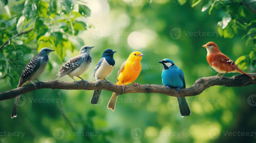

In [9]:
from fastdownload import download_url
dest = 'bird.jpg'
download_url(urls[0], dest, show_progress=False)

from fastai.vision.all import *
im = Image.open(dest)
im.to_thumb(256,256)

Now let's do the same with "forest photos":

/tmp/ipykernel_41/378111362.py:56: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:
/tmp/ipykernel_41/378111362.py:56: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


DuckDuckGo rate-limited (RatelimitException). Automatically falling back to Bing image search...


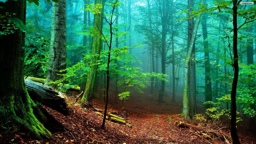

In [10]:
download_url(search_images('forest photos', max_images=1)[0], 'forest.jpg', show_progress=False)
Image.open('forest.jpg').to_thumb(256,256)

Our searches seem to be giving reasonable results, so let's grab a few examples of each of "bird" and "forest" photos, and save each group of photos to a different folder:

In [11]:
searches = 'forest','bird'
path = Path('bird_or_not')

for o in searches:
    dest = (path/o)
    dest.mkdir(exist_ok=True, parents=True)
    download_images(dest, urls=search_images(f'{o} photo'))
    time.sleep(5)
    resize_images(path/o, max_size=400, dest=path/o, max_workers=1)

/tmp/ipykernel_41/378111362.py:56: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:
/tmp/ipykernel_41/378111362.py:56: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


DuckDuckGo rate-limited (RatelimitException). Automatically falling back to Bing image search...


/tmp/ipykernel_41/378111362.py:56: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:
/tmp/ipykernel_41/378111362.py:56: RuntimeWarning: This package (`duckduckgo_search`) has been renamed to `ddgs`! Use `pip install ddgs` instead.
  with DDGS() as ddgs:


DuckDuckGo rate-limited (RatelimitException). Automatically falling back to Bing image search...


## Step 2: Train our model

Some photos might not download correctly which could cause our model training to fail, so we'll remove them:

In [12]:
failed = verify_images(get_image_files(path))
failed.map(Path.unlink)
len(failed)

0

To train a model, we'll need `DataLoaders`, which is an object that contains a *training set* (the images used to create a model) and a *validation set* (the images used to check the accuracy of a model -- not used during training). In `fastai` we can create that easily using a `DataBlock`, and view sample images from it:

/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)
/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  x = np.array(x, subok=True, copy=copy)
/usr/local/lib/python3.11/dist-packages/matplotlib/cbook.py:713: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array

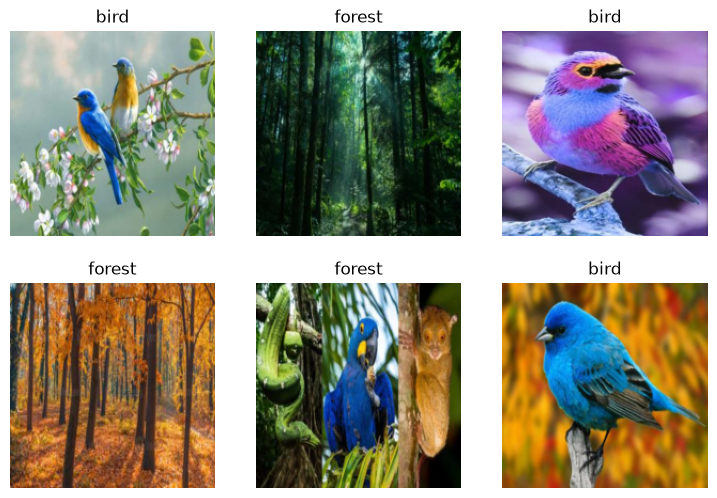

In [13]:
dls = DataBlock(
    blocks=(ImageBlock, CategoryBlock), 
    get_items=get_image_files, 
    splitter=RandomSplitter(valid_pct=0.2, seed=42),
    get_y=parent_label,
    item_tfms=[Resize(192, method='squish')]
).dataloaders(path, bs=32)

dls.show_batch(max_n=6)

Here what each of the `DataBlock` parameters means:

    blocks=(ImageBlock, CategoryBlock),

The inputs to our model are images, and the outputs are categories (in this case, "bird" or "forest").

    get_items=get_image_files, 

To find all the inputs to our model, run the `get_image_files` function (which returns a list of all image files in a path).

    splitter=RandomSplitter(valid_pct=0.2, seed=42),

Split the data into training and validation sets randomly, using 20% of the data for the validation set.

    get_y=parent_label,

The labels (`y` values) is the name of the `parent` of each file (i.e. the name of the folder they're in, which will be *bird* or *forest*).

    item_tfms=[Resize(192, method='squish')]

Before training, resize each image to 192x192 pixels by "squishing" it (as opposed to cropping it).

Now we're ready to train our model. The fastest widely used computer vision model is `resnet18`. You can train this in a few minutes, even on a CPU! (On a GPU, it generally takes under 10 seconds...)

`fastai` comes with a helpful `fine_tune()` method which automatically uses best practices for fine tuning a pre-trained model, so we'll use that.

In [14]:
learn = vision_learner(dls, resnet18, metrics=error_rate)
learn.fine_tune(3)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:04<00:00, 11.6MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,1.081832,0.491270,0.250000,00:13


epoch,train_loss,valid_loss,error_rate,time
0,0.448710,0.104920,0.050000,00:01
1,0.286489,0.025644,0.000000,00:01
2,0.202984,0.013408,0.000000,00:01


Generally when I run this I see 100% accuracy on the validation set (although it might vary a bit from run to run).

"Fine-tuning" a model means that we're starting with a model someone else has trained using some other dataset (called the *pretrained model*), and adjusting the weights a little bit so that the model learns to recognise your particular dataset. In this case, the pretrained model was trained to recognise photos in *imagenet*, and widely-used computer vision dataset with images covering 1000 categories) For details on fine-tuning and why it's important, check out the [free fast.ai course](https://course.fast.ai/).

## Step 3: Use our model (and build your own!)

Let's see what our model thinks about that bird we downloaded at the start:

In [15]:
is_bird,_,probs = learn.predict(PILImage.create('bird.jpg'))
print(f"This is a: {is_bird}.")
print(f"Probability it's a bird: {probs[0]:.4f}")

This is a: bird.
Probability it's a bird: 1.0000


Good job, resnet18. :)

So, as you see, in the space of a few years, creating computer vision classification models has gone from "so hard it's a joke" to "trivially easy and free"!

It's not just in computer vision. Thanks to deep learning, computers can now do many things which seemed impossible just a few years ago, including [creating amazing artworks](https://openai.com/dall-e-2/), and [explaining jokes](https://www.datanami.com/2022/04/22/googles-massive-new-language-model-can-explain-jokes/). It's moving so fast that even experts in the field have trouble predicting how it's going to impact society in the coming years.

One thing is clear -- it's important that we all do our best to understand this technology, because otherwise we'll get left behind!

Now it's your turn. Click "Copy & Edit" and try creating your own image classifier using your own image searches!

If you enjoyed this, please consider clicking the "upvote" button in the top-right -- it's very encouraging to us notebook authors to know when people appreciate our work.